In [1]:
import numpy as np
from statsmodels import regression
import statsmodels.api as sm
import matplotlib.pyplot as plt
import pandas as pd
import yfinance as yf

In [ ]:
# !pip install yfinance

In [2]:
aapl_df = yf.download('AAPL', start='2019-01-01', end='2021-06-12', progress=False)
aapl_df.head()

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2019-01-02,37.436913,37.657383,36.562151,36.718613,148158800
2019-01-03,33.707939,34.544770,33.662897,34.132280,365248800
2019-01-04,35.146893,35.215643,34.089596,34.262650,234428400
2019-01-07,35.068657,35.282015,34.587420,35.251196,219111200
2019-01-08,35.737186,35.990845,35.208538,35.455081,164101200


In [3]:
spy_df = yf.download('SPY', start='2019-01-01', end='2021-06-12', progress=False)
spy_df.head()

Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
2019-01-02,223.251587,224.170734,219.476892,219.503661,126925200
2019-01-03,217.924149,221.814855,217.442265,221.511441,144140700
2019-01-04,225.223679,225.866182,220.565539,220.940330,142628800
2019-01-07,226.999542,228.400547,224.599081,225.491445,103139100
2019-01-08,229.132233,229.614117,226.660395,229.176867,102512600


<Figure size 800x300 with 0 Axes>

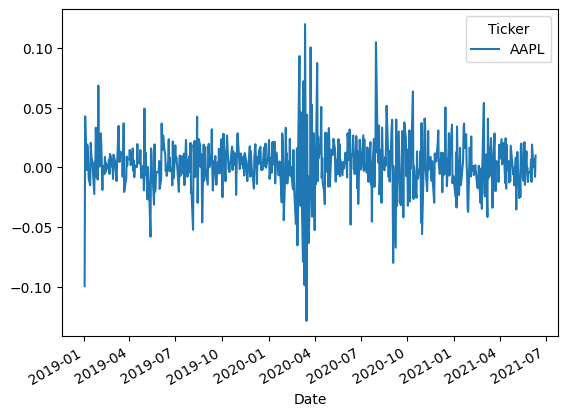

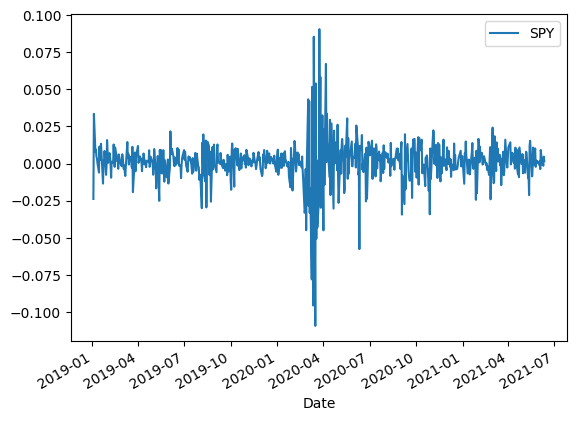

In [4]:
asset_ret = aapl_df["Close"].pct_change().dropna()
bench_ret = spy_df["Close"].pct_change().dropna()
plt.figure(figsize=(8,3))
asset_ret.plot(label="AAPL");
bench_ret.plot(label="SPY");
plt.legend()

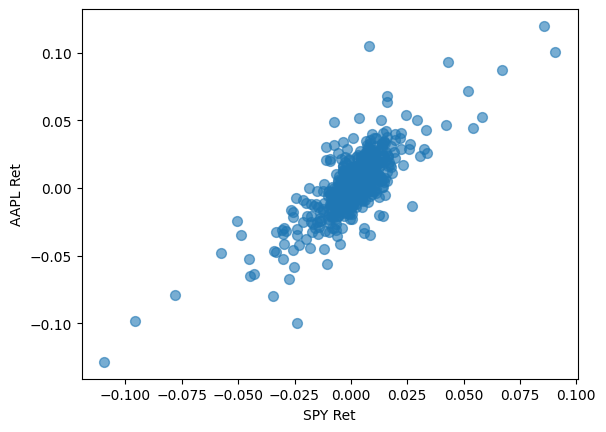

In [5]:
plt.scatter(bench_ret,asset_ret,alpha=0.6,s=50)
plt.xlabel('SPY Ret');
plt.ylabel('AAPL Ret');
plt.show()

In [6]:
AAPL = asset_ret.values
spy = bench_ret.values

# Add a constant (column of 1s for intercept)
spy_constant = sm.add_constant(spy)

# Fit regression to data
model = regression.linear_model.OLS(AAPL,spy_constant).fit()
print("Model parameters: ", model.params)
alpha , beta = model.params

Model parameters:  [9.46229541e-04 1.22144405e+00]


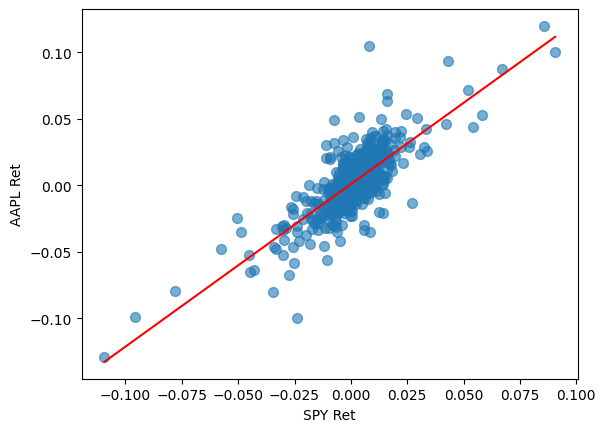

In [7]:
# Scatter Returns
plt.scatter(bench_ret,asset_ret,alpha=0.6,s=50)

# Fit Line
min_spy = bench_ret.values.min()
max_spy = bench_ret.values.max()

spy_line = np.linspace(min_spy,max_spy,100)
y = spy_line * beta + alpha

plt.plot(spy_line,y,'r')

plt.xlabel('SPY Ret')
plt.ylabel('AAPL Ret')
plt.show()